In [ ]:
ENTSOE_API_TOKEN = "YOUR_ENTSOE_API_TOKEN_HERE"  # Replace with your actual ENTSOE API

# Day Ahead Prices : The hourly clearing prices (EUR/MWh) - OK


In [ ]:
pip install entsoe-py pandas

In [ ]:

import pandas as pd
import numpy as np

from entsoe import EntsoePandasClient

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from tqdm import tqdm

import xgboost as xgb

from scipy.interpolate import PchipInterpolator


In [ ]:

api_key = ENTSOE_API_TOKEN
client = EntsoePandasClient(api_key=api_key)

country_code = 'FR'  # Bidding zone for France

start = pd.Timestamp('2020-01-01', tz='Europe/Paris')
end = pd.Timestamp('2026-02-25', tz='Europe/Paris')

try:
    # Fetches the Day-Ahead Prices
    print(f"Fetching Day-Ahead prices for {country_code}...")
    da_prices = client.query_day_ahead_prices(country_code, start=start, end=end)

    # Displays the first few rows
    print("\nData Preview:")
    print(da_prices.head())

    # Saving the data to a CSV file
    csv_filename = 'france_day_ahead_prices.csv'
    da_prices.to_csv(csv_filename, header=['Price_EUR_MWh'], index_label='Datetime')
    print(f"\nSuccess! Data saved to {csv_filename}")

except Exception as e:
    print(f"An error occurred: {e}")

Fetching Day-Ahead prices for FR...


KeyboardInterrupt: 

In [ ]:

data = pd.read_csv("/content/france_day_ahead_prices.csv",
                   parse_dates=['Datetime'],
                   index_col='Datetime').iloc[:365*4*24,:] ### DISPLAYING FIRST OBS

fig, ax = plt.subplots(figsize=(14, 6))

# Plotting the 'Price_EUR_MWh' column
ax.plot(data.index, data['Price_EUR_MWh'],
        marker='o',
        linestyle='-',
        color='#1f77b4',
        linewidth=2,
        markersize=6)

# Adding Titles and Axis Labels
ax.set_title("France (FR) Day-Ahead Electricity Prices", fontsize=16, fontweight='bold', pad=15)
ax.set_xlabel("Date & Time", fontsize=12, labelpad=10)
ax.set_ylabel("Price (EUR/MWh)", fontsize=12, labelpad=10)

# Making the axes and grid more readable
ax.grid(True, linestyle='--', alpha=0.7)

# Formating the x-axis to clearly show the hours and dates
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'))
plt.xticks(rotation=45, ha='right') # Rotating x-axis labels so they don't overlap

# Ensuring nothing gets cut off
plt.tight_layout()

# Displaying the plot
plt.show()

# Day-Ahead Total Load Forecast: The expected demand $\hat{D}_t$ in MW - OK


<>:36: SyntaxWarning: invalid escape sequence '\h'
<>:36: SyntaxWarning: invalid escape sequence '\h'
/tmp/ipython-input-2997203274.py:36: SyntaxWarning: invalid escape sequence '\h'
  ax.set_title("France (FR) Day-Ahead Total Load Forecast ($\hat{D}_t$)", fontsize=16, fontweight='bold', pad=15)


Fetching Day-Ahead Load Forecast for FR...
Success! Data saved to france_day_ahead_load_forecast.csv



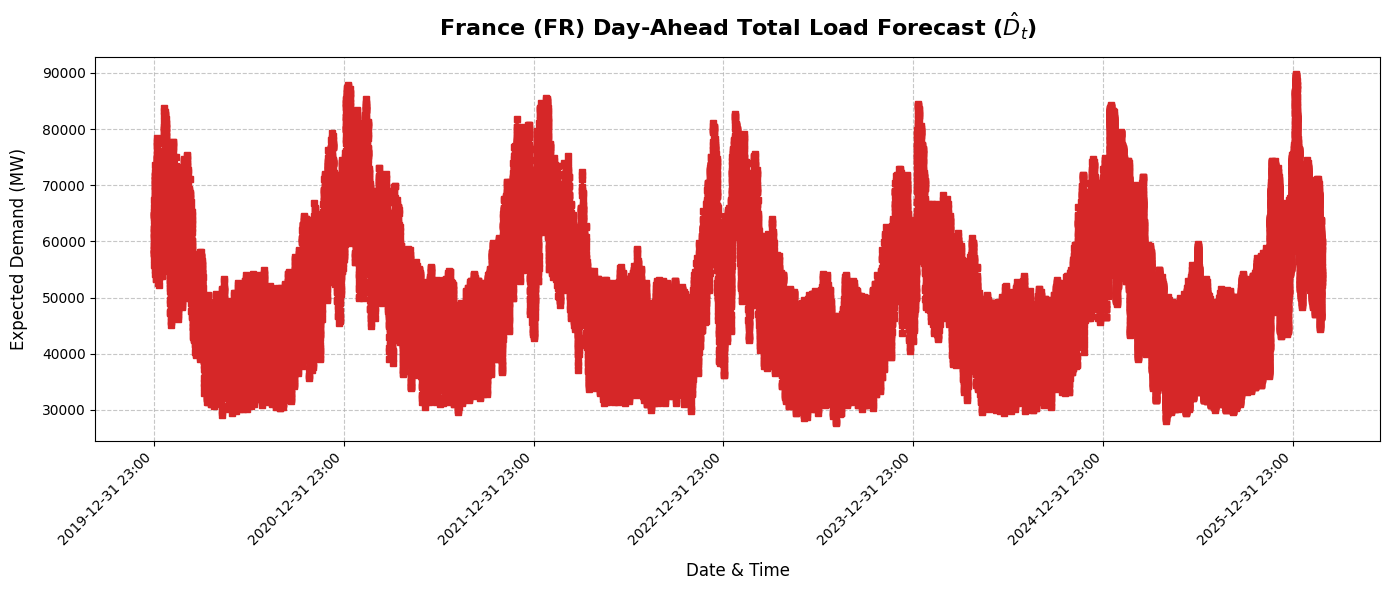

In [ ]:

api_key = ENTSOE_API_TOKEN
client = EntsoePandasClient(api_key=api_key)

# Parameters
country_code = 'FR'
start = pd.Timestamp('2020-01-01', tz='Europe/Paris')
end = pd.Timestamp('2026-02-25', tz='Europe/Paris')

try:
    # Fetching the Day-Ahead Load Forecast (Demand in MW)
    print(f"Fetching Day-Ahead Load Forecast for {country_code}...")
    da_load_forecast = client.query_load_forecast(country_code, start=start, end=end)

    # Saving to CSV
    csv_filename = 'france_day_ahead_load_forecast.csv'
    da_load_forecast.to_csv(csv_filename, header=['Forecasted_Load_MW'], index_label='Datetime')
    print(f"Success! Data saved to {csv_filename}\n")

    # Plotting the Load Forecast Data
    fig, ax = plt.subplots(figsize=(14, 6))

    ax.plot(da_load_forecast.index, da_load_forecast,
            marker='s',          # Using squares ('s') to visually distinguish from price dots
            linestyle='-',
            color='#d62728',     # A bold red color for demand
            linewidth=2,
            markersize=5)

    # Adding Titles and Axis Labels
    ax.set_title("France (FR) Day-Ahead Total Load Forecast ($\hat{D}_t$)", fontsize=16, fontweight='bold', pad=15)
    ax.set_xlabel("Date & Time", fontsize=12, labelpad=10)
    ax.set_ylabel("Expected Demand (MW)", fontsize=12, labelpad=10)

    # Formatting axes and grid
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'))
    plt.xticks(rotation=45, ha='right')

    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"An error occurred: {e}")

# Day-Ahead Generation Forecasts for Wind and Solar: The intermittent renewable generation $W_t$ in MW - OK

Fetching Wind and Solar Forecasts for FR...

Data Preview:
                           Solar  Wind Offshore  Wind Onshore  Total_W_t
2020-01-01 00:00:00+01:00    0.0            NaN       2966.13    2966.13
2020-01-01 01:00:00+01:00    0.0            NaN       2992.79    2992.79
2020-01-01 02:00:00+01:00    0.0            NaN       2857.19    2857.19
2020-01-01 03:00:00+01:00    0.0            NaN       2720.88    2720.88
2020-01-01 04:00:00+01:00    0.0            NaN       2584.39    2584.39

Success! Data saved to france_wind_solar_forecast.csv



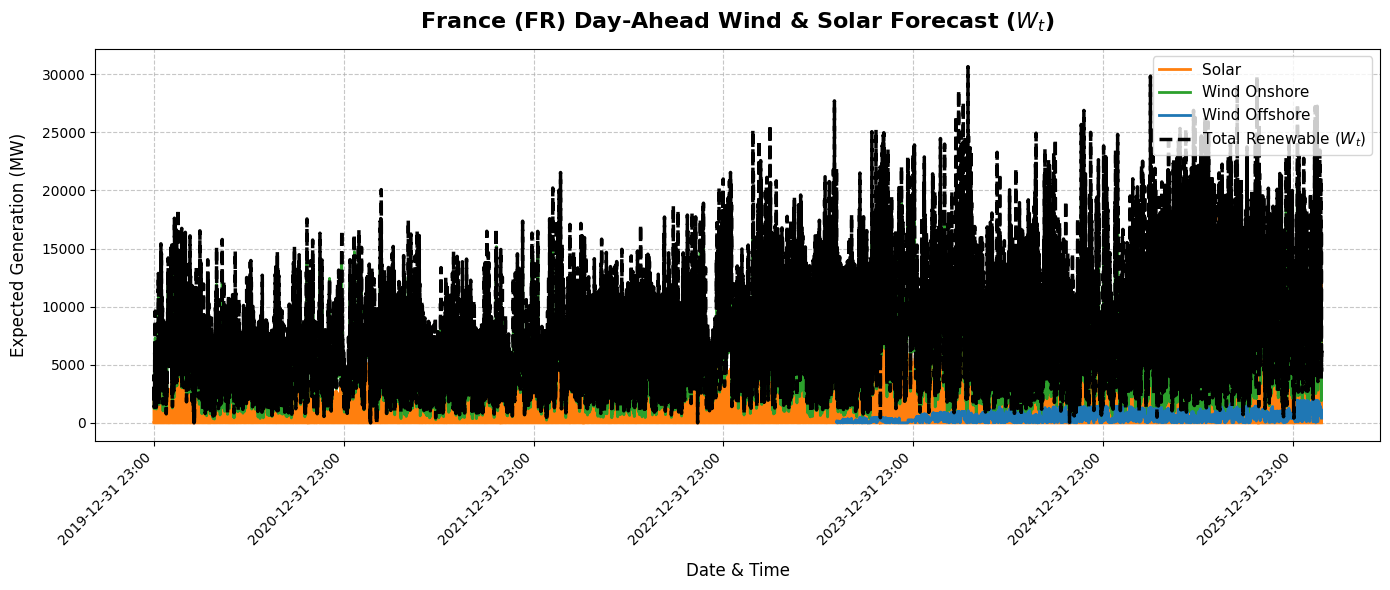

In [ ]:
api_key = ENTSOE_API_TOKEN
client = EntsoePandasClient(api_key=api_key)

# Parameters
country_code = 'FR'
start = pd.Timestamp('2020-01-01', tz='Europe/Paris')
end = pd.Timestamp('2026-02-25', tz='Europe/Paris')

try:
    # Fetching the Wind and Solar Forecasts
    print(f"Fetching Wind and Solar Forecasts for {country_code}...")
    ws_forecast = client.query_wind_and_solar_forecast(country_code, start=start, end=end)

    # Computing Total Intermittent Generation (W_t) by summing all columns
    ws_forecast['Total_W_t'] = ws_forecast.sum(axis=1)

    # Displaying the first few rows to see the column breakdown
    print("\nData Preview:")
    print(ws_forecast.head())

    # Saving to CSV
    csv_filename = 'france_wind_solar_forecast.csv'
    ws_forecast.to_csv(csv_filename, index_label='Datetime')
    print(f"\nSuccess! Data saved to {csv_filename}\n")

    # Plotting the Generation Forecasts
    fig, ax = plt.subplots(figsize=(14, 6))

    # Plot Solar
    if 'Solar' in ws_forecast.columns:
        ax.plot(ws_forecast.index, ws_forecast['Solar'],
                color='#ff7f0e', label='Solar', linewidth=2)

    # Plot Wind Onshore
    if 'Wind Onshore' in ws_forecast.columns:
        ax.plot(ws_forecast.index, ws_forecast['Wind Onshore'],
                color='#2ca02c', label='Wind Onshore', linewidth=2)

    # Plot Wind Offshore (if applicable)
    if 'Wind Offshore' in ws_forecast.columns:
        ax.plot(ws_forecast.index, ws_forecast['Wind Offshore'],
                color='#1f77b4', label='Wind Offshore', linewidth=2)

    # Plot Total W_t
    ax.plot(ws_forecast.index, ws_forecast['Total_W_t'],
            color='black', linestyle='--', label='Total Renewable ($W_t$)', linewidth=2.5)

    # Adding Titles, Labels, and Legend
    ax.set_title("France (FR) Day-Ahead Wind & Solar Forecast ($W_t$)", fontsize=16, fontweight='bold', pad=15)
    ax.set_xlabel("Date & Time", fontsize=12, labelpad=10)
    ax.set_ylabel("Expected Generation (MW)", fontsize=12, labelpad=10)
    ax.legend(loc='upper right', fontsize=11)

    # Formatting axes and grid
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'))
    plt.xticks(rotation=45, ha='right')

    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"An error occurred: {e}")

# Actual Generation per Production Type: To see the ex-post realization of the energy mix. - OK

Fetching Actual Generation for FR...

Production Types found:
['Biomass', 'Energy storage', 'Fossil Gas', 'Fossil Hard coal', 'Fossil Oil', 'Hydro Pumped Storage', 'Hydro Run-of-river and poundage', 'Hydro Water Reservoir', 'Nuclear', 'Solar', 'Waste', 'Wind Offshore', 'Wind Onshore']

Success! Data saved to france_actual_generation_mix.csv



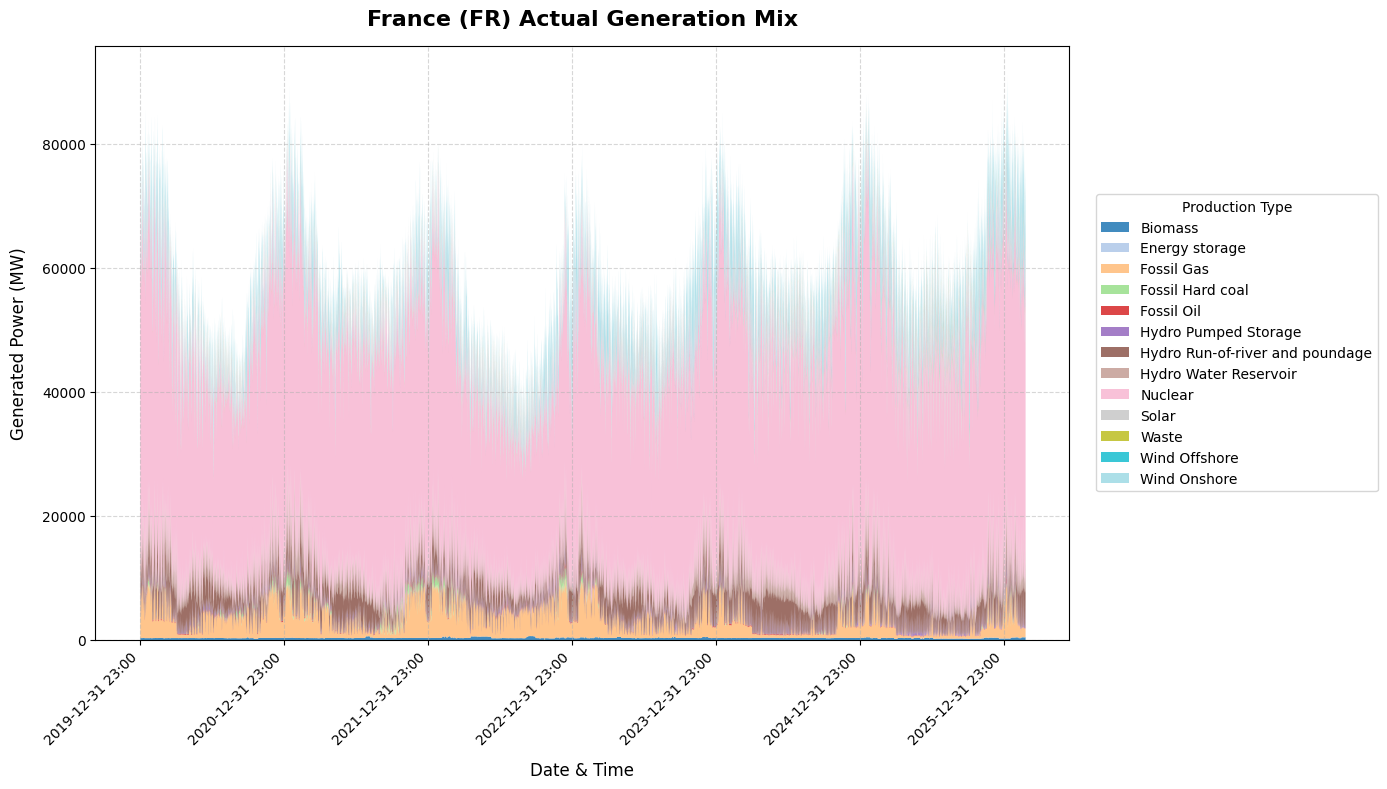

In [ ]:

api_key = ENTSOE_API_TOKEN
client = EntsoePandasClient(api_key=api_key)

# Parameters
country_code = 'FR'

start = pd.Timestamp('2020-01-01', tz='Europe/Paris')
end = pd.Timestamp('2026-02-24', tz='Europe/Paris')

try:
    # Fetching Actual Generation per Production Type
    print(f"Fetching Actual Generation for {country_code}...")
    actual_gen = client.query_generation(country_code, start=start, end=end)

    # Sometimes ENTSO-E returns a MultiIndex column (e.g., Generation vs Consumption for Pumped Hydro).
    # We will filter to keep only the 'Actual Aggregated' generation.
    if isinstance(actual_gen.columns, pd.MultiIndex):
        actual_gen = actual_gen.xs('Actual Aggregated', level=1, axis=1)

    # Filling missing values with 0 (sometimes offline plants return NaN instead of 0)
    actual_gen = actual_gen.fillna(0)

    # Displaying the production types available
    print("\nProduction Types found:")
    print(list(actual_gen.columns))

    # Saving to CSV
    csv_filename = 'france_actual_generation_mix.csv'
    actual_gen.to_csv(csv_filename, index_label='Datetime')
    print(f"\nSuccess! Data saved to {csv_filename}\n")

    # Plot the Energy Mix as a Stacked Area Chart
    fig, ax = plt.subplots(figsize=(14, 8))

    actual_gen.plot(kind='area', ax=ax, colormap='tab20', alpha=0.85, linewidth=0)

    # Adding Titles and Axis Labels
    ax.set_title("France (FR) Actual Generation Mix", fontsize=16, fontweight='bold', pad=15)
    ax.set_xlabel("Date & Time", fontsize=12, labelpad=10)
    ax.set_ylabel("Generated Power (MW)", fontsize=12, labelpad=10)

    # Moving the legend outside the plot area so it doesn't cover the data
    ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=10, title="Production Type")

    # Formatting axes and grid
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'))
    plt.xticks(rotation=45, ha='right')

    # Adjusting layout to fit the external legend
    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"An error occurred: {e}")

# Actual Battery Storage Dispatch: RTE - OK


1. Downloading Historical Dataset (2020-2024)...
2. Downloading Real-Time Dataset (2025-Present)...
3. Merging datasets...

Success! Built a continuous timeline of 53951 hours.
Data saved to france_master_hourly_storage_2020_present.csv



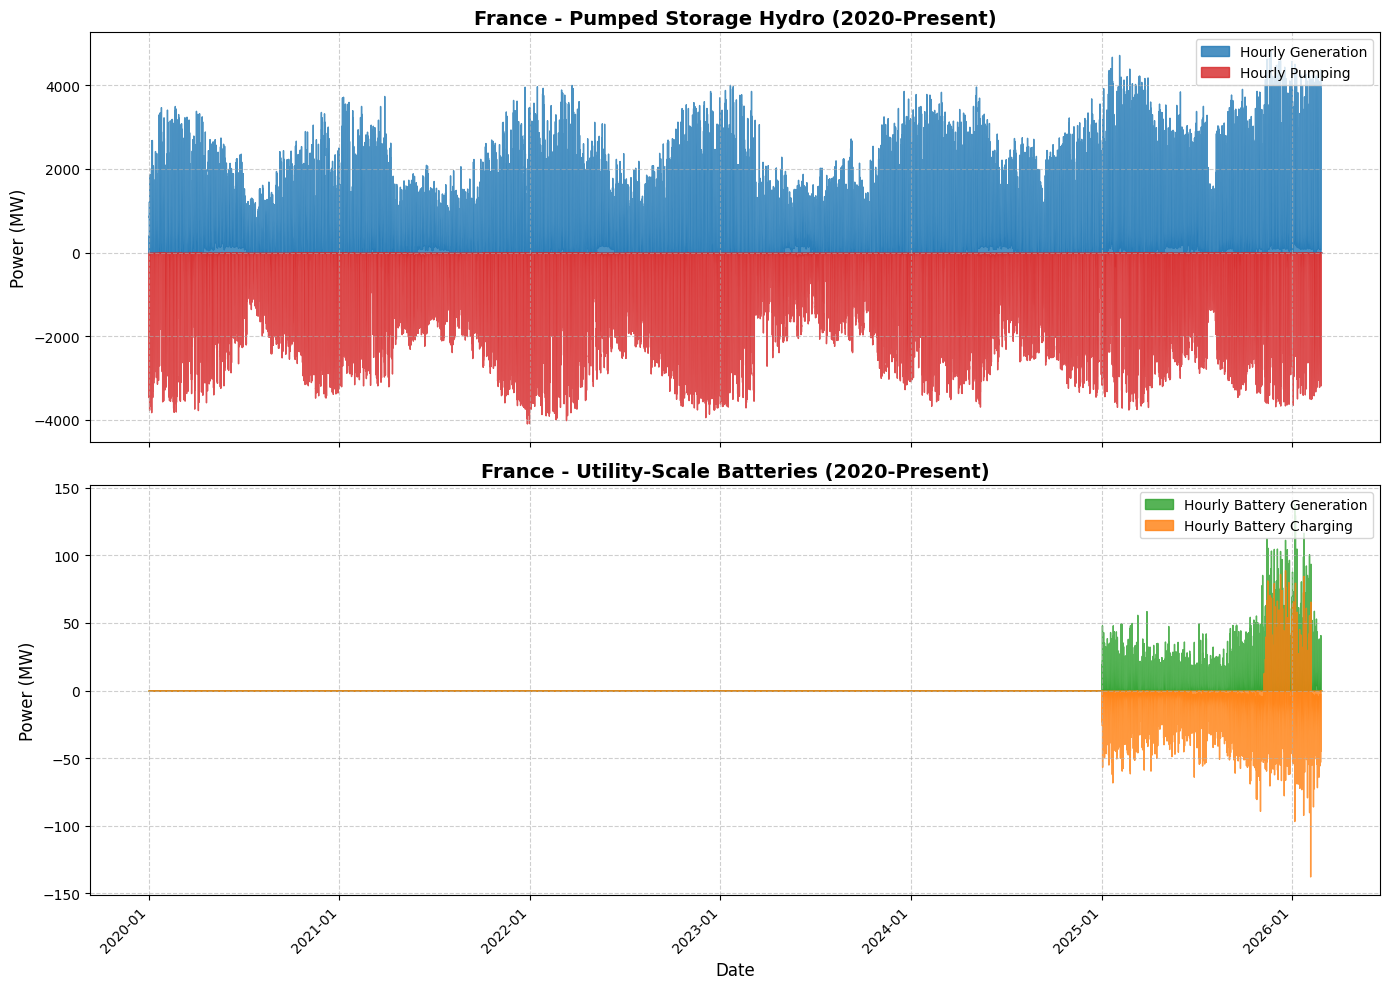

In [ ]:
url_cons = "https://odre.opendatasoft.com/api/explore/v2.1/catalog/datasets/eco2mix-national-cons-def/exports/csv"
url_tr = "https://odre.opendatasoft.com/api/explore/v2.1/catalog/datasets/eco2mix-national-tr/exports/csv"
params = "?lang=en&timezone=UTC&use_labels=false&delimiter=%3B"

def fetch_and_clean_eco2mix(url, start_year=None):
    """Downloads RTE data, cleans timestamps, and handles the 15/45-min artificial zeros."""
    df = pd.read_csv(url + params, sep=';', low_memory=False)
    df['date_heure'] = pd.to_datetime(df['date_heure'], utc=True)
    df = df.dropna(subset=['date_heure']).sort_values('date_heure').set_index('date_heure')

    if start_year:
        df = df.loc[df.index >= pd.Timestamp(f'{start_year}-01-01', tz='UTC')]

    cols_to_keep = ['pompage', 'hydraulique_step_turbinage', 'stockage_batterie', 'destockage_batterie']

    # Ensures all columns exist, even if missing in the specific export
    for col in cols_to_keep:
        if col not in df.columns:
            df[col] = np.nan

    df = df[cols_to_keep]

    # Replacing 0.0 with NaN when minute is 15 or 45
    mask_15_45 = df.index.minute.isin([15, 45])
    for col in cols_to_keep:
        df.loc[mask_15_45 & (df[col] == 0), col] = np.nan

    # Resampling to hourly
    return df.resample('h').mean()

try:
    print("1. Downloading Historical Dataset (2020-2024)...")
    df_historical = fetch_and_clean_eco2mix(url_cons, start_year=2020)

    print("2. Downloading Real-Time Dataset (2025-Present)...")
    df_realtime = fetch_and_clean_eco2mix(url_tr)

    print("3. Merging datasets...")
    # combine_first prefers df_realtime, but fills missing older dates from df_historical
    master_storage = df_realtime.combine_first(df_historical)

    # Fills remaining NaNs (like pre-2025 batteries) with 0
    master_storage = master_storage.fillna(0)

    # Saving to CSV
    csv_filename = 'france_master_hourly_storage_2020_present.csv'
    master_storage.to_csv(csv_filename)
    print(f"\nSuccess! Built a continuous timeline of {len(master_storage)} hours.")
    print(f"Data saved to {csv_filename}\n")

    # 4. Plot the Unified Dataset
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

    # --- Top Plot: Pumped Hydro ---
    ax1.fill_between(master_storage.index, master_storage['hydraulique_step_turbinage'], 0,
                     color='#1f77b4', alpha=0.8, label='Hourly Generation')
    ax1.fill_between(master_storage.index, master_storage['pompage'], 0,
                     color='#d62728', alpha=0.8, label='Hourly Pumping')

    ax1.set_title("France - Pumped Storage Hydro (2020-Present)", fontsize=14, fontweight='bold')
    ax1.set_ylabel("Power (MW)", fontsize=12)
    ax1.legend(loc='upper right')
    ax1.grid(True, linestyle='--', alpha=0.6)

    # --- Bottom Plot: Batteries ---
    ax2.fill_between(master_storage.index, master_storage['destockage_batterie'], 0,
                     color='#2ca02c', alpha=0.8, label='Hourly Battery Generation')
    ax2.fill_between(master_storage.index, master_storage['stockage_batterie'], 0,
                     color='#ff7f0e', alpha=0.8, label='Hourly Battery Charging')

    ax2.set_title("France - Utility-Scale Batteries (2020-Present)", fontsize=14, fontweight='bold')
    ax2.set_ylabel("Power (MW)", fontsize=12)
    ax2.set_xlabel("Date", fontsize=12)
    ax2.legend(loc='upper right')
    ax2.grid(True, linestyle='--', alpha=0.6)

    ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.xticks(rotation=45, ha='right')

    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"An error occurred: {e}")

## Simulating 2020-2024 battery with hypotheses

In [ ]:

print("1. Loading CSVs into DataFrames...")
# parse_dates=[0] tells pandas the first column contains dates
# index_col=0 tells pandas to set those dates as the index right away
load_df = pd.read_csv("/content/france_day_ahead_load_forecast.csv", index_col=0, parse_dates=True)
prices_df = pd.read_csv("/content/france_day_ahead_prices.csv", index_col=0, parse_dates=True)
wind_solar_df = pd.read_csv("/content/france_wind_solar_forecast.csv", index_col=0, parse_dates=True)
storage_df = pd.read_csv("/content/france_master_hourly_storage_2020_present.csv", index_col=0, parse_dates=True)

# Standardize Timezones and Frequencies
def clean_and_align(df):
    """Converts the index to strict UTC and enforces a 1-hour frequency."""
    # This automatically converts +01:00 (Winter) and +02:00 (Summer) strings directly to UTC
    df.index = pd.to_datetime(df.index, utc=True)

    # Resamples to hourly to ensure the indexes are perfectly uniform
    # We use .mean() to handle any potential duplicated timestamps during DST changes
    return df.resample('h').mean()

print("2. Aligning timezones and standardizing to 1-hour intervals...")
load_df = clean_and_align(load_df)
prices_df = clean_and_align(prices_df)
wind_solar_df = clean_and_align(wind_solar_df)
storage_df = clean_and_align(storage_df)

# Merge Everything Together
print("3. Merging datasets into a single Master DataFrame...")
# pd.concat with axis=1 acts like a SQL Full Outer Join based on the datetime index
features_df = pd.concat([prices_df, load_df, wind_solar_df, storage_df], axis=1)

# Final Cleanup
# We only want to keep rows where we actually have Price and Load data
# (This trims off any extra storage data that goes further back or forward than ENTSO-E pull)
features_df = features_df.dropna(subset=['Price_EUR_MWh', 'Forecasted_Load_MW'])

# Fill remaining NaNs (e.g., if Wind Offshore was missing for an hour, or early 2020 battery data) with 0
features_df = features_df.fillna(0)

# Display the final structure
print("\nSuccess! Here is the layout of your final Machine Learning dataset:")
print(features_df.info())

# Save the final Master ML dataset
csv_filename = '/content/master_features_2020_2026.csv'
features_df.to_csv(csv_filename)
print(f"\nFinal dataset saved to {csv_filename}!")

1. Loading CSVs into DataFrames...
2. Aligning timezones and standardizing to 1-hour intervals...
3. Merging datasets into a single Master DataFrame...

Success! Here is the layout of your final Machine Learning dataset:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 53919 entries, 2019-12-31 23:00:00+00:00 to 2026-02-24 22:00:00+00:00
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Price_EUR_MWh               53919 non-null  float64
 1   Forecasted_Load_MW          53919 non-null  float64
 2   Solar                       53919 non-null  float64
 3   Wind Offshore               53919 non-null  float64
 4   Wind Onshore                53919 non-null  float64
 5   Total_W_t                   53919 non-null  float64
 6   pompage                     53919 non-null  float64
 7   hydraulique_step_turbinage  53919 non-null  float64
 8   stockage_batterie           53919 non-null  floa

1. Engineering Advanced Features...
2. Aligning to Empirical Data Volume...
3. Training the Model (Strictly absolute-price blind)...
4. Running the Physical & Economic Simulator...
5. Plotting Final Results...


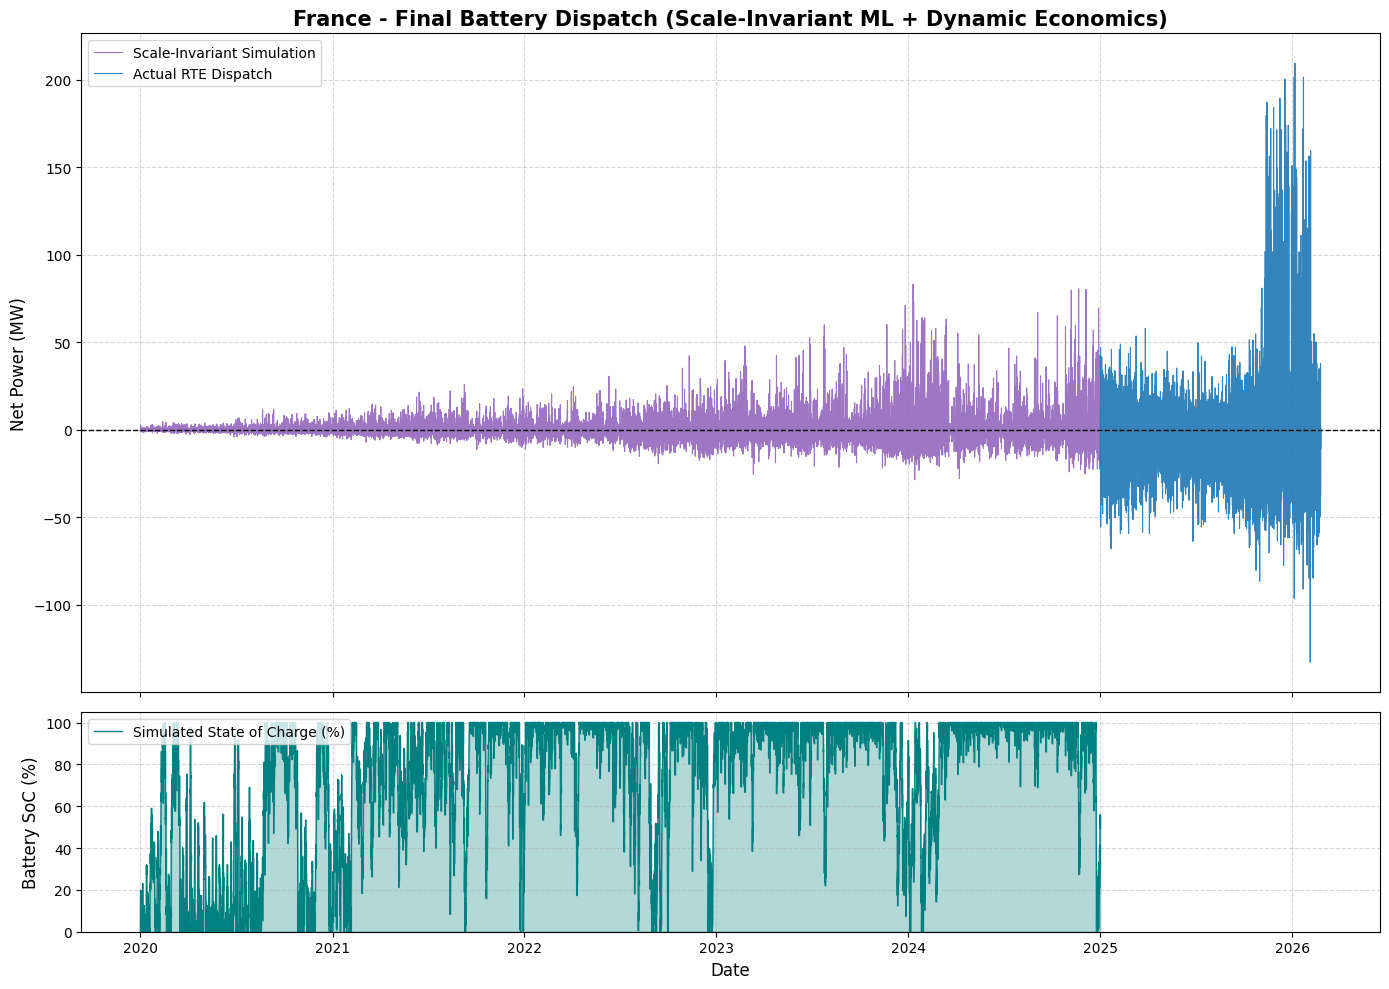


Saved fully processed dataset to /content/perfect_battery_dataset.csv!


In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

# ==============================================================================
# 1. LOAD DATA & INITIAL FEATURE ENGINEERING
# ==============================================================================
features_df = pd.read_csv('/content/master_features_2020_2026.csv', index_col=0, parse_dates=True)
features_df.index = pd.to_datetime(features_df.index, utc=True)

print("1. Engineering Advanced Features...")

# Base Features
features_df['Total_W_t'] = features_df[['Solar', 'Wind Onshore']].sum(axis=1)
features_df['Residual_Load'] = features_df['Forecasted_Load_MW'] - features_df['Total_W_t']
features_df['Hour'] = features_df.index.hour
features_df['DayOfWeek'] = features_df.index.dayofweek

# --- 24H ARBITRAGE SIGNALS ---
features_df['Max_Price_Next_24h'] = features_df['Price_EUR_MWh'].iloc[::-1].rolling(window=24, min_periods=1).max().iloc[::-1]
features_df['Min_Price_Next_24h'] = features_df['Price_EUR_MWh'].iloc[::-1].rolling(window=24, min_periods=1).min().iloc[::-1]

features_df['Hold_Signal_24h'] = features_df['Max_Price_Next_24h'] - features_df['Price_EUR_MWh']
features_df['Wait_To_Charge_Signal_24h'] = features_df['Price_EUR_MWh'] - features_df['Min_Price_Next_24h']

# --- SCALE-INVARIANT SIGNALS ---
rolling_min = features_df['Price_EUR_MWh'].rolling(window=24, min_periods=1).min()
rolling_max = features_df['Price_EUR_MWh'].rolling(window=24, min_periods=1).max()
features_df['Price_Position_24h'] = (features_df['Price_EUR_MWh'] - rolling_min) / (rolling_max - rolling_min + 1e-5)

roll_min_load = features_df['Residual_Load'].rolling(24*7, min_periods=1).min()
roll_max_load = features_df['Residual_Load'].rolling(24*7, min_periods=1).max()
features_df['Relative_Res_Load'] = (features_df['Residual_Load'] - roll_min_load) / (roll_max_load - roll_min_load + 1e-5)

features_df['Daily_Mean_Price'] = features_df['Price_EUR_MWh'].rolling(24, min_periods=1).mean()
features_df = features_df.bfill().ffill()


# ==============================================================================
# 2. EMPIRICAL CAPACITY SCALING
# ==============================================================================
print("2. Aligning to Empirical Data Volume...")
features_df['Net_Battery_Dispatch'] = features_df['destockage_batterie'] + features_df['stockage_batterie']
real_max_dispatch = features_df.loc['2025':, 'Net_Battery_Dispatch'].abs().max()

capacity_points = {
    '2020-01-01': real_max_dispatch * 0.05,
    '2021-01-01': real_max_dispatch * 0.15,
    '2022-01-01': real_max_dispatch * 0.35,
    '2023-01-01': real_max_dispatch * 0.60,
    '2024-01-01': real_max_dispatch * 0.85,
    '2025-01-01': real_max_dispatch,
    '2026-01-01': real_max_dispatch * 1.10
}
cap_series = pd.Series(capacity_points)
cap_series.index = pd.to_datetime(cap_series.index, utc=True)
features_df['Empirical_Capacity'] = cap_series.resample('h').interpolate(method='linear').reindex(features_df.index).ffill().bfill()


# ==============================================================================
# 3. XGBOOST TRAINING (Scale-Invariant)
# ==============================================================================
print("3. Training the Model (Strictly absolute-price blind)...")
features_df['Dispatch_Factor'] = features_df['Net_Battery_Dispatch'] / features_df['Empirical_Capacity']
train_df = features_df.loc['2025':'2026'].dropna(subset=['Dispatch_Factor'])

# THE FIX: Strictly these 6 scale-invariant features. No lag_lead_features!
ml_features = [
    'Price_Position_24h', 'Relative_Res_Load', 'Hour', 'DayOfWeek',
    'Hold_Signal_24h', 'Wait_To_Charge_Signal_24h'
]

X_train = train_df[ml_features]
y_train = train_df['Dispatch_Factor']

# Reverted to the exact parameters that generated your beautiful plot
model = xgb.XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6, subsample=0.8, objective='reg:squarederror')
model.fit(X_train, y_train)

features_df['Predicted_Factor'] = model.predict(features_df[ml_features])


# ==============================================================================
# 4. PHYSICAL & ECONOMIC SIMULATOR
# ==============================================================================
print("4. Running the Physical & Economic Simulator...")
class PhysicalBatterySimulator:
    def __init__(self, duration_hours=2.0, round_trip_efficiency=0.85):
        self.duration_hours = duration_hours
        self.one_way_eff = np.sqrt(round_trip_efficiency)

    def simulate(self, df):
        constrained_dispatch = np.zeros(len(df))
        soc_tracker = np.zeros(len(df))
        current_energy_mwh = 0.0

        requested_factors = df['Predicted_Factor'].values
        capacities = df['Empirical_Capacity'].values
        max_prices = df['Max_Price_Next_24h'].values
        min_prices = df['Min_Price_Next_24h'].values
        daily_means = df['Daily_Mean_Price'].values

        for i in range(len(df)):
            power_cap = capacities[i]
            if power_cap <= 0:
                continue

            energy_cap = power_cap * self.duration_hours

            # Dynamic Deadband
            dynamic_deadband = max(5.0, daily_means[i] * 0.15)
            daily_spread = max_prices[i] - min_prices[i]

            if daily_spread < dynamic_deadband:
                requested_mw = 0.0
            else:
                requested_mw = requested_factors[i] * power_cap

            actual_mw = 0.0
            if requested_mw < 0:
                available_space = energy_cap - current_energy_mwh
                max_grid_pull = available_space / self.one_way_eff
                actual_mw = max(requested_mw, -power_cap, -max_grid_pull)
                current_energy_mwh += abs(actual_mw) * self.one_way_eff
            elif requested_mw > 0:
                max_grid_push = current_energy_mwh * self.one_way_eff
                actual_mw = min(requested_mw, power_cap, max_grid_push)
                current_energy_mwh -= (actual_mw / self.one_way_eff)

            constrained_dispatch[i] = actual_mw
            soc_tracker[i] = current_energy_mwh / energy_cap

        return constrained_dispatch, soc_tracker

simulator = PhysicalBatterySimulator()
features_df['Ultimate_Battery_Dispatch'], features_df['State_of_Charge'] = simulator.simulate(features_df)

# Merge real data for 2025 onwards
features_df.loc['2025':, 'Ultimate_Battery_Dispatch'] = features_df.loc['2025':, 'Net_Battery_Dispatch']


# ==============================================================================
# 5. FINAL PLOTTING & EXPORT
# ==============================================================================
print("5. Plotting Final Results...")
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), gridspec_kw={'height_ratios': [3, 1]}, sharex=True)

simulated = features_df.loc['2020':'2024', 'Ultimate_Battery_Dispatch']
actual = features_df.loc['2025':, 'Ultimate_Battery_Dispatch']

ax1.plot(simulated.index, simulated, color='#9467bd', alpha=0.9, linewidth=0.8, label='Scale-Invariant Simulation')
ax1.plot(actual.index, actual, color='#1f77b4', alpha=0.9, linewidth=0.8, label='Actual RTE Dispatch')

ax1.set_title("France - Final Battery Dispatch (Scale-Invariant ML + Dynamic Economics)", fontsize=15, fontweight='bold')
ax1.set_ylabel("Net Power (MW)", fontsize=12)
ax1.axhline(0, color='black', linewidth=1, linestyle='--')
ax1.legend(loc='upper left')
ax1.grid(True, linestyle='--', alpha=0.5)

simulated_soc = features_df.loc['2020':'2024', 'State_of_Charge']
ax2.fill_between(simulated_soc.index, simulated_soc * 100, 0, color='teal', alpha=0.3)
ax2.plot(simulated_soc.index, simulated_soc * 100, color='teal', linewidth=1, label='Simulated State of Charge (%)')
ax2.set_ylabel("Battery SoC (%)", fontsize=12)
ax2.set_xlabel("Date", fontsize=12)
ax2.set_ylim(0, 105)
ax2.legend(loc='upper left')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Clean export
final_cols = ['Price_EUR_MWh', 'Forecasted_Load_MW', 'Solar', 'Wind Onshore', 'Wind Offshore', 'pompage', 'hydraulique_step_turbinage', 'Ultimate_Battery_Dispatch']
cols_to_save = [c for c in final_cols if c in features_df.columns]
features_df[cols_to_save].to_csv('/content/perfect_battery_dataset.csv')
print("\nSaved fully processed dataset to /content/perfect_battery_dataset.csv!")

## Download final data

In [ ]:
import pandas as pd
from google.colab import files

print("Extracting full gross storage dispatch data...")
df = pd.read_csv('/content/perfect_battery_dataset.csv', index_col=0, parse_dates=True)

# 1. We need to split our 'Ultimate_Battery_Dispatch' back into its components
# Charging is negative, Discharging is positive.
storage_data = pd.DataFrame(index=df.index)

# Battery Components
storage_data['Battery_Discharge_MW'] = df['Ultimate_Battery_Dispatch'].clip(lower=0)
storage_data['Battery_Charge_MW'] = df['Ultimate_Battery_Dispatch'].clip(upper=0)

# Pumped Hydro Components (already separated in your master dataset)
storage_data['Hydro_Discharge_MW'] = df['hydraulique_step_turbinage']
storage_data['Hydro_Charge_MW'] = df['pompage']

# 2. Add Net columns for reference
storage_data['Battery_Net_MW'] = df['Ultimate_Battery_Dispatch']
storage_data['Hydro_Net_MW'] = df['hydraulique_step_turbinage'] + df['pompage']

# 3. Clean up the export
csv_filename = 'france_gross_hourly_storage_dispatch.csv'
storage_data.to_csv(csv_filename)

# 4. Trigger Download
print(f"File ready: {csv_filename}. Downloading now...")
files.download(csv_filename)

Extracting full gross storage dispatch data...
File ready: france_gross_hourly_storage_dispatch.csv. Downloading now...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Outages / Unavailabilities: Data on when nuclear or gas plants go offline, which drastically shifts the residual demand curve. - OK

In [ ]:
"""
EXCEL FILE DOWNLOADE DE : https://iip.cloud-rte-france.com/indisponibilite-production
"""
# Loading manual Excel file
file_path = '/content/France_Indisponibilites_Production.xlsx'
df_raw = pd.read_excel(file_path)

# Defining the Mapping of Interest
# We map the French names in your Excel to clean English feature names
fuel_map = {
    'Nucléaire': 'Nuclear_Outage_MW',
    'Gaz fossile': 'Gas_Outage_MW',
    'Charbon': 'Coal_Outage_MW',
    'Fioul': 'Oil_Outage_MW',
    'Hydraulique STEP': 'Hydro_STEP_Outage_MW'
}

# Standardizing Columns
start_col = 'Début de la période (UTC)'
end_col = 'Fin de la période (UTC)'
val_col = 'Capacité indisponible'
type_col = 'Filière de production'

df_raw[start_col] = pd.to_datetime(df_raw[start_col], utc=True)
df_raw[end_col] = pd.to_datetime(df_raw[end_col], utc=True)

# Filtering for active reports and fuels in our map
df = df_raw[
    (df_raw['Statut'] == 'Actif') &
    (df_raw[type_col].isin(fuel_map.keys()))
].copy()

# Creating Hourly Index (2020-01-01 to Present)
start_date = pd.Timestamp('2020-01-01', tz='UTC')
end_date = df[end_col].max()
hourly_index = pd.date_range(start=start_date, end=end_date, freq='h', tz='UTC')

# Initializing DataFrame with zeros
outage_master = pd.DataFrame(index=hourly_index)
for col in fuel_map.values():
    outage_master[col] = 0.0

print(f"Processing outages for: {', '.join(fuel_map.keys())}...")

# Populating the Time Series
for fuel_fr, col_name in fuel_map.items():
    fuel_df = df[df[type_col] == fuel_fr]

    for _, row in fuel_df.iterrows():
        s = max(row[start_col].floor('h'), start_date)
        e = min(row[end_col].ceil('h'), end_date)
        val = row[val_col]

        if e > s:
            # Add unavailable MW to the specific range
            # Using loc[s:e] inclusive of the start of the final hour
            outage_master.loc[s:e - pd.Timedelta(hours=1), col_name] += val

# 6. Save and Export
outage_master.to_csv('france_comprehensive_outages_2020_2026.csv')
print("Success! Created comprehensive outage series.")
print(outage_master.tail())

/usr/local/lib/python3.12/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


Processing outages for: Nucléaire, Gaz fossile, Charbon, Fioul, Hydraulique STEP...
Success! Created comprehensive outage series.
                           Nuclear_Outage_MW  Gas_Outage_MW  Coal_Outage_MW  \
2029-08-05 18:00:00+00:00             1330.0            0.0             0.0   
2029-08-05 19:00:00+00:00             1330.0            0.0             0.0   
2029-08-05 20:00:00+00:00             1330.0            0.0             0.0   
2029-08-05 21:00:00+00:00             1330.0            0.0             0.0   
2029-08-05 22:00:00+00:00                0.0            0.0             0.0   

                           Oil_Outage_MW  Hydro_STEP_Outage_MW  
2029-08-05 18:00:00+00:00            0.0                   0.0  
2029-08-05 19:00:00+00:00            0.0                   0.0  
2029-08-05 20:00:00+00:00            0.0                   0.0  
2029-08-05 21:00:00+00:00            0.0                   0.0  
2029-08-05 22:00:00+00:00            0.0                   0.0  


# Merit Order Curves :) modified - Ok


In [ ]:
"""
Step 1: Data Preparation and Deduplication
First, we need to clean the base merit order to isolate unique plants and align the timezones of your dynamic datasets.
"""

# Loading Data
base_mo = pd.read_csv("/content/merit_order_France_CFD_paper.csv")
outages = pd.read_csv("/content/france_comprehensive_outages_2020_2026.csv", parse_dates=[0], index_col=0)
re_forecast = pd.read_csv("/content/france_wind_solar_forecast.csv", parse_dates=[0], index_col=0)

# Cleaning Base Merit Order
# The dataset has multiple years (cyear) for the same plants. Keepping the most recent data (e.g., 2018).
installed_plants = base_mo[base_mo['cyear'] == 2018.0].copy()

# Keeping only necessary columns to speed up processing
installed_plants = installed_plants[['name_p', 'tech_key', 'capacity', 'srmc_eur_mwh']].dropna(subset=['capacity'])

# Computing total installed capacity per technology to use for proportional outage distribution
tech_totals = installed_plants.groupby('tech_key')['capacity'].sum()

# Aligning Timezones
# Outages are in UTC, RE Forecast is in UTC+1. we convert everything to UTC for consistency.
outages.index = pd.to_datetime(outages.index, utc=True)
re_forecast.index = pd.to_datetime(re_forecast.index, utc=True)

# Combining dynamic data into a single dataframe for easy iteration
dynamic_data = pd.merge(outages, re_forecast[['Total_W_t']], left_index=True, right_index=True, how='inner')


In [ ]:
"""
Step 2: The Hourly Construction Logic
Since we only have aggregate outages by technology (e.g., Nuclear_Outage_MW), the most robust way to apply this to plant-level data
without knowing exactly which plant is down is to reduce the capacity of all plants in that technology proportionally.
"""

def build_hourly_curve_with_jitter(installed_df, tech_totals, row_data, jitter_pct=0.05):
    """
    Constructs the merit order curve for a single hour with economic jitter.
    jitter_pct = 0.05 means +/- 5% random variation applied to SRMC.
    """
    # Creating a fresh copy of the installed base for this hour
    hourly_stack = installed_df.copy()

    # Applying proportional outages (same as before)
    outage_map = {
        'nuclear': row_data.get('Nuclear_Outage_MW', 0),
        'ccgt': row_data.get('Gas_Outage_MW', 0),
        'coal_sc': row_data.get('Coal_Outage_MW', 0),
        'oil': row_data.get('Oil_Outage_MW', 0),
        'hydro': row_data.get('Hydro_STEP_Outage_MW', 0)
    }

    for tech, outage_mw in outage_map.items():
        if tech in tech_totals and tech_totals[tech] > 0:
            availability = max(0.0, 1.0 - (outage_mw / tech_totals[tech]))
            mask = hourly_stack['tech_key'] == tech
            hourly_stack.loc[mask, 'capacity'] *= availability

    # Injecting Wind and Solar as a 0-marginal cost block (same as before)
    vre_capacity = row_data.get('Total_W_t', 0)
    if vre_capacity > 0:
        vre_row = pd.DataFrame([{
            'name_p': 'Wind_Solar_Forecast',
            'tech_key': 'VRE',
            'capacity': vre_capacity,
            'srmc_eur_mwh': 0.0 # Bidding at zero
        }])
        hourly_stack = pd.concat([vre_row, hourly_stack], ignore_index=True)

    # Removing any plants with 0 capacity after adjustments
    hourly_stack = hourly_stack[hourly_stack['capacity'] > 0]

    # ==========================================
    # 3. THE JITTER LOGIC
    # ==========================================
    # We apply noise to everything EXCEPT Wind/Solar to preserve the 0-cost block
    non_vre_mask = hourly_stack['tech_key'] != 'VRE'

    # Generate random multipliers between (1 - jitter) and (1 + jitter)
    noise = np.random.uniform(1.0 - jitter_pct, 1.0 + jitter_pct, size=non_vre_mask.sum())

    # Apply the noise to the SRMC
    hourly_stack.loc[non_vre_mask, 'srmc_eur_mwh'] *= noise
    # ==========================================

    # Sort by the NEW jittered SRMC to build the Merit Order
    hourly_stack = hourly_stack.sort_values(by='srmc_eur_mwh', ascending=True).reset_index(drop=True)

    # Calculate Cumulative Capacity
    hourly_stack['cum_capacity_mw'] = hourly_stack['capacity'].cumsum()

    return hourly_stack

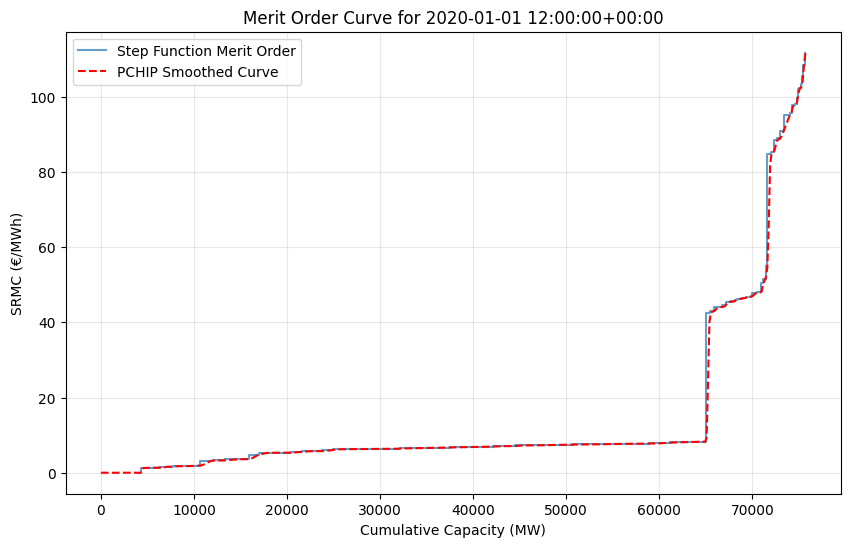

In [ ]:
"""
Step 3: PCHIP Interpolation
PCHIP is excellent for this because it preserves monotonicity (it won't create artificial price drops between two expensive plants).
The PCHIP function requires strictly increasing x-values (cumulative capacity).
"""

def fit_pchip_curve(hourly_stack):
    """
    Fits a PCHIP interpolator to the hourly merit order step-function.
    """
    # X: Cumulative Capacity, Y: SRMC
    x = hourly_stack['cum_capacity_mw'].values
    y = hourly_stack['srmc_eur_mwh'].values

    # PCHIP requires strictly increasing x arrays.
    # To ensure the curve starts at 0 capacity, we prepend a (0, minimum_price) point.
    x_clean = np.insert(x, 0, 0.0)
    y_clean = np.insert(y, 0, y[0])

    # Fit the interpolator
    pchip_func = PchipInterpolator(x_clean, y_clean, extrapolate=False)

    return pchip_func



# To use it:
# jan_smoothed_func = fit_smooth_curve(jan_mo_stack, smoothing_factor=100000)

# --- Example of processing a single hour and plotting ---
# Take the first hour in your combined dataset
sample_timestamp = dynamic_data.index[12]
sample_row = dynamic_data.iloc[12]

# Build the stack
hourly_mo_stack = build_hourly_curve_with_jitter(installed_plants, tech_totals, sample_row)

# Fit the smooth curve
smoothed_curve_func = fit_pchip_curve(hourly_mo_stack)

# Generate points for plotting
cap_range = np.linspace(0, hourly_mo_stack['cum_capacity_mw'].max(), 500)
smoothed_prices = smoothed_curve_func(cap_range)

# Plotting the Step Function vs Smoothed PCHIP
plt.figure(figsize=(10, 6))
plt.step(hourly_mo_stack['cum_capacity_mw'], hourly_mo_stack['srmc_eur_mwh'],
         where='pre', label='Step Function Merit Order', alpha=0.7)
plt.plot(cap_range, smoothed_prices, color='red', label='PCHIP Smoothed Curve', linestyle='--')
plt.title(f"Merit Order Curve for {sample_timestamp}")
plt.xlabel("Cumulative Capacity (MW)")
plt.ylabel("SRMC (€/MWh)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

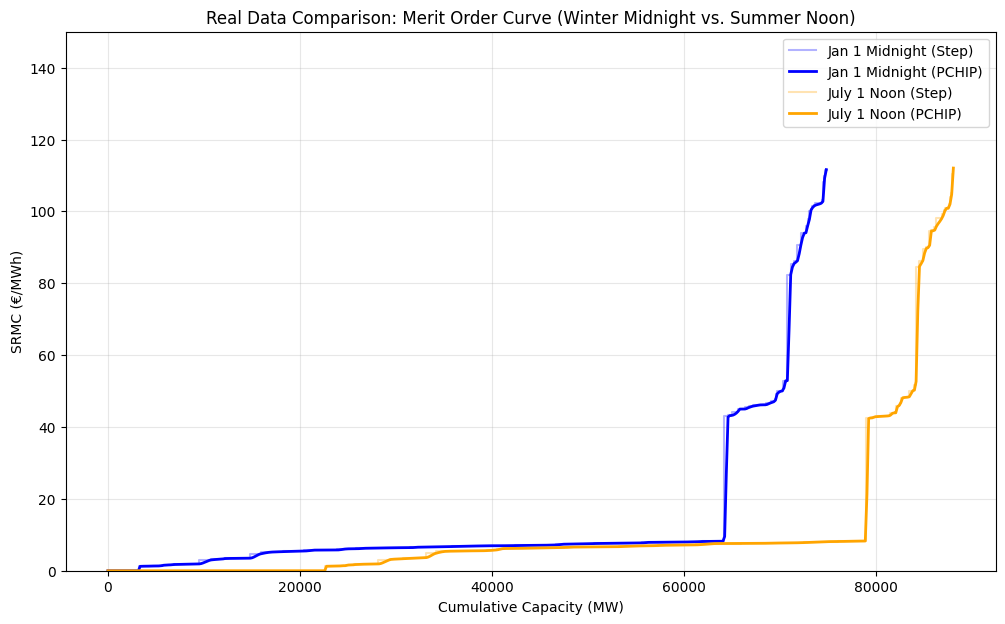

In [ ]:
# Select the exact timestamps from real data
jan_timestamp = pd.to_datetime('2020-01-01 00:00:00+00:00')
july_timestamp = pd.to_datetime('2025-07-14 12:00:00+00:00')

# Extract the real rows of data for these hours
real_jan_data = dynamic_data.loc[jan_timestamp]
real_july_data = dynamic_data.loc[july_timestamp]

# Build the hourly stacks using the real data
jan_mo_stack = build_hourly_curve_with_jitter(installed_plants, tech_totals, real_jan_data)
july_mo_stack = build_hourly_curve_with_jitter(installed_plants, tech_totals, real_july_data)

# Fit the PCHIP curves
jan_smoothed_func = fit_pchip_curve(jan_mo_stack)
july_smoothed_func = fit_pchip_curve(july_mo_stack)

# Generate points for plotting
# Use a common max capacity to make the x-axis comparable
max_cap = max(jan_mo_stack['cum_capacity_mw'].max(), july_mo_stack['cum_capacity_mw'].max())
cap_range = np.linspace(0, max_cap, 500)

jan_smoothed_prices = jan_smoothed_func(cap_range)
july_smoothed_prices = july_smoothed_func(cap_range)

# Plot the comparison
plt.figure(figsize=(12, 7))

# Plot January (Winter Midnight)
plt.step(jan_mo_stack['cum_capacity_mw'], jan_mo_stack['srmc_eur_mwh'],
         where='pre', color='blue', alpha=0.3, label='Jan 1 Midnight (Step)')
plt.plot(cap_range, jan_smoothed_prices, color='blue', linestyle='-', linewidth=2, label='Jan 1 Midnight (PCHIP)')

# Plot July (Summer Noon)
plt.step(july_mo_stack['cum_capacity_mw'], july_mo_stack['srmc_eur_mwh'],
         where='pre', color='orange', alpha=0.3, label='July 1 Noon (Step)')
plt.plot(cap_range, july_smoothed_prices, color='orange', linestyle='-', linewidth=2, label='July 1 Noon (PCHIP)')

plt.title("Real Data Comparison: Merit Order Curve (Winter Midnight vs. Summer Noon)")
plt.xlabel("Cumulative Capacity (MW)")
plt.ylabel("SRMC (€/MWh)")
plt.ylim(0, 150) # Cap Y-axis to see the inframarginal/marginal intersection clearly
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:

# Define the standardized capacity grid
# (e.g., 0 to 90,000 MW in 1,000 MW steps)
capacity_grid = np.arange(0, 91000, 1000)

# List to store the evaluated prices for each hour
standardized_curves = []

print("Generating hourly merit order curves on a standardized grid...")
for timestamp, row_data in tqdm(dynamic_data.iterrows(), total=len(dynamic_data)):

    # Build the stack using your jitter function
    hourly_mo_stack = build_hourly_curve_with_jitter(installed_plants, tech_totals, row_data, jitter_pct=0.05)

    # Fit the PCHIP curve
    pchip_func = fit_pchip_curve(hourly_mo_stack)

    # Evaluate the smoothed curve on our standardized grid
    prices_on_grid = pchip_func(capacity_grid)

    # Handle Scarcity/Extrapolation
    # Because extrapolate=False, PCHIP returns NaN for grid points beyond the hourly max capacity.
    # We replace these NaNs with the maximum SRMC in the stack for that hour.
    max_hourly_price = hourly_mo_stack['srmc_eur_mwh'].max()
    prices_on_grid = np.where(np.isnan(prices_on_grid), max_hourly_price, prices_on_grid)

    # Store the array of prices
    standardized_curves.append(prices_on_grid)

# Create the final Matrix DataFrame
col_names = [f"Price_at_{cap}MW" for cap in capacity_grid]
merit_order_matrix = pd.DataFrame(standardized_curves, index=dynamic_data.index, columns=col_names)

print("\nDone! Matrix shape:", merit_order_matrix.shape)
print("Preview of your standardized merit order matrix:")
display(merit_order_matrix.head())


Generating hourly merit order curves on a standardized grid...


100%|██████████| 53724/53724 [08:50<00:00, 101.22it/s]



Done! Matrix shape: (53724, 91)
Preview of your standardized merit order matrix:


,Price_at_0MW,Price_at_1000MW,Price_at_2000MW,Price_at_3000MW,Price_at_4000MW,Price_at_5000MW,Price_at_6000MW,Price_at_7000MW,Price_at_8000MW,Price_at_9000MW,...,Price_at_81000MW,Price_at_82000MW,Price_at_83000MW,Price_at_84000MW,Price_at_85000MW,Price_at_86000MW,Price_at_87000MW,Price_at_88000MW,Price_at_89000MW,Price_at_90000MW
2020-01-01 00:00:00+00:00,0.0,0.0,0.0,0.000000,1.285512,1.347799,1.599769,1.731500,1.766073,1.835309,...,112.295908,112.295908,112.295908,112.295908,112.295908,112.295908,112.295908,112.295908,112.295908,112.295908
2020-01-01 01:00:00+00:00,0.0,0.0,0.0,0.000000,1.308094,1.346908,1.590064,1.713595,1.758266,1.811973,...,110.026990,110.026990,110.026990,110.026990,110.026990,110.026990,110.026990,110.026990,110.026990,110.026990
2020-01-01 02:00:00+00:00,0.0,0.0,0.0,0.316924,1.321132,1.351331,1.566230,1.734550,1.800048,1.866029,...,109.556486,109.556486,109.556486,109.556486,109.556486,109.556486,109.556486,109.556486,109.556486,109.556486
2020-01-01 03:00:00+00:00,0.0,0.0,0.0,1.238629,1.274133,1.372178,1.604181,1.767730,1.825688,1.880431,...,111.694636,111.694636,111.694636,111.694636,111.694636,111.694636,111.694636,111.694636,111.694636,111.694636
2020-01-01 04:00:00+00:00,0.0,0.0,0.0,1.251086,1.325873,1.418291,1.609815,1.795516,1.866448,1.926077,...,110.621828,110.621828,110.621828,110.621828,110.621828,110.621828,110.621828,110.621828,110.621828,110.621828


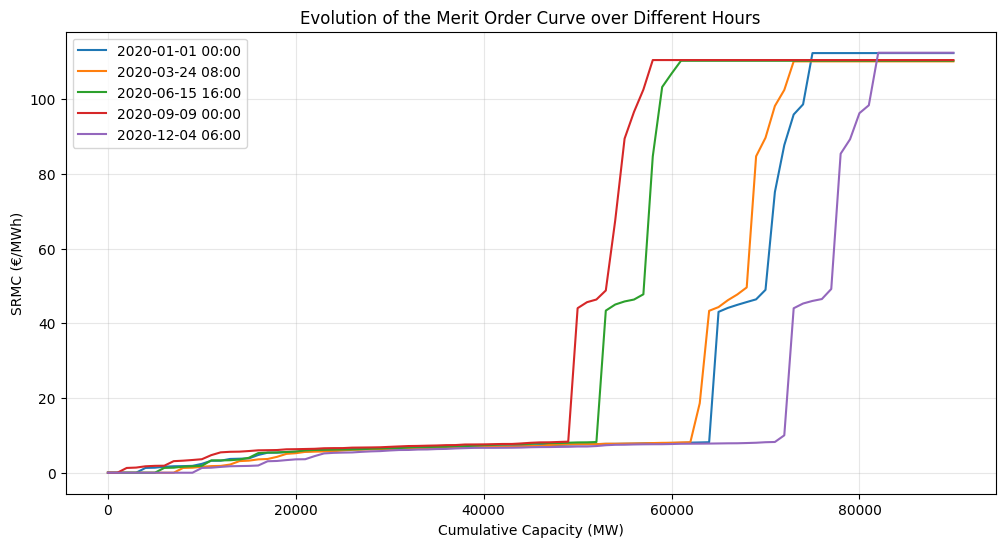

In [ ]:
plt.figure(figsize=(12, 6))
# Sample 5 different hours (e.g., winter, spring, summer, fall)
for timestamp, prices in merit_order_matrix.iloc[[0, 2000, 4000, 6000, 8000]].iterrows():
    plt.plot(capacity_grid, prices.values, label=timestamp.strftime('%Y-%m-%d %H:%M'))

plt.xlabel("Cumulative Capacity (MW)")
plt.ylabel("SRMC (€/MWh)")
plt.title("Evolution of the Merit Order Curve over Different Hours")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:

# Saving the output to your environment
merit_order_matrix.to_csv("/content/smoothed_merit_order_matrix.csv")